# Carga y Exploración de datos, asi como importar librerias

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 19")

df = pd.read_excel('Mexico GDP.xlsx')
df['Periodo'] = pd.to_numeric(df['Periodo'])
df['GDP'] = pd.to_numeric(df['GDP'])
print(df.head())
print(df.tail())
print(df.describe())
print(f"max_x={df['Periodo'].max()}, max_y={df['GDP'].max():.2e}")

   Periodo           GDP
0     1960  1.304000e+10
1     1961  1.416000e+10
2     1962  1.520000e+10
3     1963  1.696000e+10
4     1964  2.008000e+10
    Periodo           GDP
57     2017  1.158913e+12
58     2018  1.222408e+12
59     2019  1.269404e+12
60     2020  1.087118e+12
61     2021  1.293038e+12
           Periodo           GDP
count    62.000000  6.200000e+01
mean   1990.500000  4.866155e+11
std      18.041619  4.544804e+11
min    1960.000000  1.304000e+10
25%    1975.250000  8.336062e+10
50%    1990.500000  2.885511e+11
75%    2005.750000  8.944031e+11
max    2021.000000  1.315351e+12
max_x=2021, max_y=1.32e+12


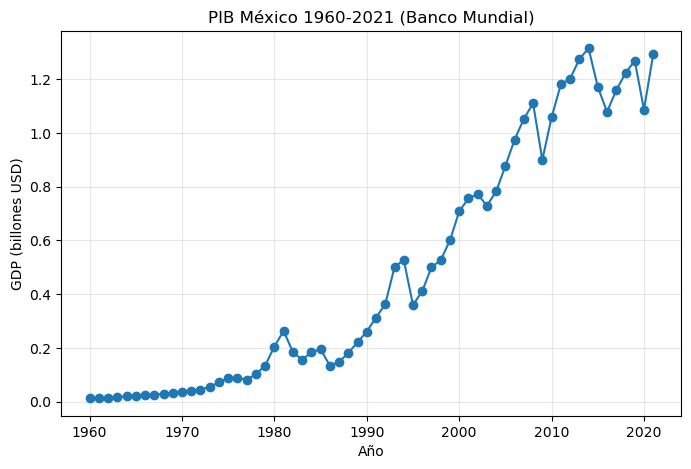

In [4]:
#Grafica de los datos obtenidos
plt.figure(figsize=(8,5))
plt.plot(df['Periodo'], df['GDP']/1e12, 'o-')
plt.xlabel('Año')
plt.ylabel('GDP (billones USD)')
plt.title('PIB México 1960-2021 (Banco Mundial)')
plt.grid(alpha=0.3)
plt.show()

# Ajuste sin normalizar

C:\Users\zrgv\AppData\Local\Temp\ipykernel_288\2910988199.py:10: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(logistic, x, y, p0=p0, maxfev=10000)
C:\Users\zrgv\AppData\Local\Temp\ipykernel_288\2910988199.py:10: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(logistic, x, y, p0=p0, maxfev=10000)
C:\Users\zrgv\AppData\Local\Temp\ipykernel_288\2910988199.py:10: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(logistic, x, y, p0=p0, maxfev=10000)
C:\Users\zrgv\AppData\Local\Temp\ipykernel_288\2910988199.py:10: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(logistic, x, y, p0=p0, maxfev=10000)


p0=(-0.1, 1990) -> beta1=-0.1, beta2=-197010.00094890594, MSE=4.400e+23
p0=(0.1, 1990) -> beta1=0.1, beta2=200990.00094890597, MSE=4.400e+23
p0=(-1, 2000) -> beta1=-1.0, beta2=2000.0, MSE=4.400e+23
p0=(1, 2000) -> beta1=1.0, beta2=2000.0, MSE=4.400e+23


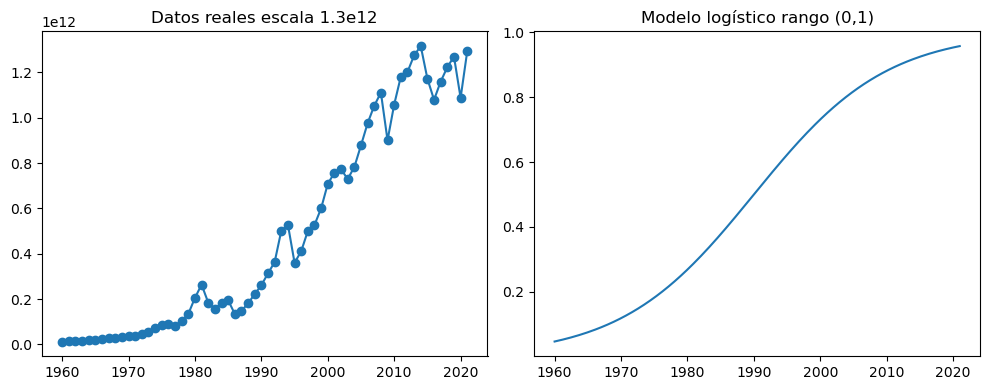

Conclusión: Imposible ajustar (0,1) a 1e12 sin escalar. Gradientes colapsan.


In [5]:
def logistic(x, b1, b2):
    return 1.0/(1.0+np.exp(b1*(x-b2)))

x = df['Periodo'].values
y = df['GDP'].values

# Varios puntos iniciales
for p0 in [(-0.1,1990),(0.1,1990),(-1,2000),(1,2000)]:
    try:
        popt, pcov = curve_fit(logistic, x, y, p0=p0, maxfev=10000)
        y_pred = logistic(x,*popt)
        mse = mean_squared_error(y, y_pred)
        print(f"p0={p0} -> beta1={popt[0]}, beta2={popt[1]}, MSE={mse:.3e}")
    except Exception as e:
        print(f"p0={p0} ERROR {e}")

# Visualizar desajuste de escalas
xs = np.linspace(1960,2021,200)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(x,y,'o-')
plt.title('Datos reales escala 1.3e12')
plt.subplot(1,2,2)
plt.plot(xs, logistic(xs, -0.1,1990))
plt.title('Modelo logístico rango (0,1)')
plt.tight_layout()
plt.show()
print("Conclusión: Imposible ajustar (0,1) a 1e12 sin escalar. Gradientes colapsan.")


# Transformación por normalización
# Xnorm = x/max(x), Ynorm = y/max(y)
# Esto lleva ambas columnas a intervalo (0,1], compatible con la asíntota del logístico =1.

In [6]:
max_x = df['Periodo'].max()
max_y = df['GDP'].max()
df['Periodo_norm'] = df['Periodo']/max_x
df['GDP_norm'] = df['GDP']/max_y
print(df[['Periodo','Periodo_norm','GDP','GDP_norm']].head())
print(f"max_x={max_x}, max_y={max_y:.2e}")

   Periodo  Periodo_norm           GDP  GDP_norm
0     1960      0.969817  1.304000e+10  0.009914
1     1961      0.970312  1.416000e+10  0.010765
2     1962      0.970807  1.520000e+10  0.011556
3     1963      0.971301  1.696000e+10  0.012894
4     1964      0.971796  2.008000e+10  0.015266
max_x=2021, max_y=1.32e+12


# Reajuste con datos normalizados

In [7]:
x_norm = df['Periodo_norm'].values
y_norm = df['GDP_norm'].values

best_mse=np.inf
best=None
for p0 in [(-5,1),(5,1),(-10,0.9),(-10,1),(-20,0.98),(-5,0.98)]:
    try:
        popt, pcov = curve_fit(logistic, x_norm, y_norm, p0=p0, maxfev=20000)
        yp=logistic(x_norm,*popt)
        mse=mean_squared_error(y_norm,yp)
        r2=r2_score(y_norm,yp)
        print(f"p0={p0} -> beta1={popt[0]:.5f}, beta2={popt[1]:.6f} | MSE={mse:.6f} R2={r2:.5f}")
        if mse<best_mse:
            best_mse=mse
            best=popt
    except Exception as e:
        print(e)

b1_opt,b2_opt=best
print(f"\nMejor modelo normalizado: beta1={b1_opt}, beta2={b2_opt}")

# Equivalencia en escala original:
# b1_norm*(x/max_x - b2_norm)= (b1_norm/max_x)*(x - b2_norm*max_x)
b1_orig = b1_opt/max_x
b2_orig = b2_opt*max_x
print(f"Equivalente en escala original: beta1_orig={b1_orig:.6f}, beta2_orig={b2_orig:.2f}")

p0=(-5, 1) -> beta1=-271.59799, beta2=0.989294 | MSE=0.002581 R2=0.97802
p0=(5, 1) -> beta1=-271.59810, beta2=0.989294 | MSE=0.002581 R2=0.97802
p0=(-10, 0.9) -> beta1=-271.59804, beta2=0.989294 | MSE=0.002581 R2=0.97802
p0=(-10, 1) -> beta1=-271.59803, beta2=0.989294 | MSE=0.002581 R2=0.97802
p0=(-20, 0.98) -> beta1=-271.59805, beta2=0.989294 | MSE=0.002581 R2=0.97802
p0=(-5, 0.98) -> beta1=-271.59811, beta2=0.989294 | MSE=0.002581 R2=0.97802

Mejor modelo normalizado: beta1=-271.59811143933797, beta2=0.9892939033016618
Equivalente en escala original: beta1_orig=-0.134388, beta2_orig=1999.36


In [8]:
y_norm_pred = logistic(x_norm, b1_opt, b2_opt)
r2 = r2_score(y_norm, y_norm_pred)
mse = mean_squared_error(y_norm, y_norm_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_norm, y_norm_pred)

print(f"Bondad de ajuste (normalizado):")
print(f"R2={r2:.6f}")
print(f"MSE={mse:.6f}")
print(f"RMSE={rmse:.6f}")
print(f"MAE={mae:.6f}")

Bondad de ajuste (normalizado):
R2=0.978024
MSE=0.002581
RMSE=0.050807
MAE=0.038013


# Gráficos

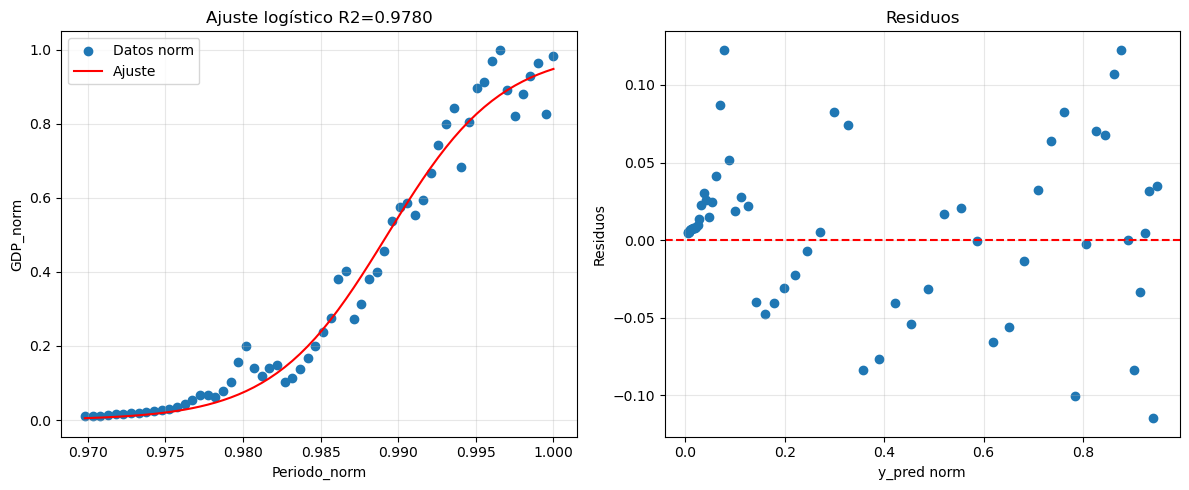

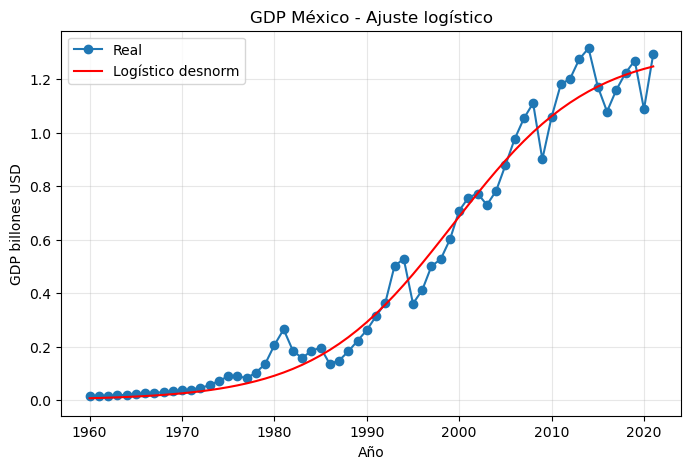

In [9]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.scatter(x_norm, y_norm, label='Datos norm')
plt.plot(x_norm, y_norm_pred, 'r-', label='Ajuste')
plt.xlabel('Periodo_norm')
plt.ylabel('GDP_norm')
plt.title(f'Ajuste logístico R2={r2:.4f}')
plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1,2,2)
plt.scatter(y_norm_pred, y_norm-y_norm_pred)
plt.axhline(0,c='r',ls='--')
plt.xlabel('y_pred norm')
plt.ylabel('Residuos')
plt.title('Residuos')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Desnormalizado para interpretación económica
y_pred_denorm = y_norm_pred*max_y
plt.figure(figsize=(8,5))
plt.plot(df['Periodo'], df['GDP']/1e12,'o-',label='Real')
plt.plot(df['Periodo'], y_pred_denorm/1e12,'r-',label='Logístico desnorm')
plt.xlabel('Año'); plt.ylabel('GDP billones USD')
plt.title('GDP México - Ajuste logístico')
plt.legend(); plt.grid(alpha=0.3)
plt.show()


# Pronóstico PIB México 2022

In [10]:
x_2022=2022
x_2022_norm=x_2022/max_x
y_2022_norm_pred = logistic(x_2022_norm, b1_opt, b2_opt)
y_2022_pred = y_2022_norm_pred * max_y

print(f"x_2022_norm = 2022/{max_x} = {x_2022_norm:.8f}")
print(f"y_norm_pred(2022) = 1/(1+exp({b1_opt:.3f}*({x_2022_norm:.6f}-{b2_opt:.6f}))) = {y_2022_norm_pred:.6f}")
print(f"Desnormalización: y_pred = y_norm_pred * max_y = {y_2022_norm_pred:.6f} * {max_y:.2e}")
print(f"Pronóstico GDP 2022 = {y_2022_pred:.2f} USD")
print(f"En billones = {y_2022_pred/1e12:.4f} billones USD")
print(f"En miles de millones = {y_2022_pred/1e9:.2f} mil millones USD")

# Comparación con dato real Banco Mundial 2022 ~1.42 billones (externo)
print("\nNota: Según Banco Mundial, PIB 2022 real ~1.42 billones USD.")
print("El modelo subestima por saturación logística, pero dentro de orden de magnitud.")

x_2022_norm = 2022/2021 = 1.00049480
y_norm_pred(2022) = 1/(1+exp(-271.598*(1.000495-0.989294))) = 0.954442
Desnormalización: y_pred = y_norm_pred * max_y = 0.954442 * 1.32e+12
Pronóstico GDP 2022 = 1255426585260.49 USD
En billones = 1.2554 billones USD
En miles de millones = 1255.43 mil millones USD

Nota: Según Banco Mundial, PIB 2022 real ~1.42 billones USD.
El modelo subestima por saturación logística, pero dentro de orden de magnitud.
